# 04. Deep Dive — Nominal


In [42]:
from math import ceil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from propensity.overview import build_dunnhumby_overview
from propensity.overview.activity_dashboard import (
    load_transaction_activity_dashboard,
    plot_transaction_activity_dashboard,
)
from propensity.schema.dunnhumby import DUNNHUMBY_CATALOG

In [43]:
raw_dir = Path("../data/raw/Dunnhumby")
report = build_dunnhumby_overview(raw_dir=raw_dir)

In [ ]:
product_taxonomy = pd.read_csv(
    raw_dir / "product.csv",
    usecols=[
        "PRODUCT_ID", "MANUFACTURER", "DEPARTMENT",
        "COMMODITY_DESC", "SUB_COMMODITY_DESC",
    ],
)
transaction_detail = pd.read_csv(
    raw_dir / "transaction_data.csv",
    usecols=[
        "household_key", "BASKET_ID", "PRODUCT_ID", "SALES_VALUE",
    ],
)


### 7.4. Category concentration và Pareto

Ba taxonomy `DEPARTMENT`, `COMMODITY_DESC`, `SUB_COMMODITY_DESC` được xếp hạng theo số dòng transaction. Coverage top-10 và Pareto vì vậy phản ánh mức độ tập trung của hoạt động mua, không chỉ số category trong product catalog.

In [63]:
CATEGORY_COLUMNS = ["DEPARTMENT", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]
CATEGORY_TOP_N = 15
category_lookup = product_taxonomy.drop_duplicates("PRODUCT_ID").set_index("PRODUCT_ID")
for category_column in CATEGORY_COLUMNS:
    transaction_detail[category_column] = (
        transaction_detail["PRODUCT_ID"]
        .map(category_lookup[category_column])
        .fillna("<MISSING>")
        .astype("category")
    )

category_profiles = {}
category_coverage_rows = []
for category_column in CATEGORY_COLUMNS:
    line_counts = transaction_detail[category_column].value_counts(dropna=False)
    product_counts = (
        product_taxonomy[category_column]
        .fillna("<MISSING>")
        .value_counts(dropna=False)
    )
    profile = line_counts.rename("n_lines").to_frame()
    profile["n_products"] = profile.index.map(product_counts).fillna(0).astype("int64")
    profile["line_pct"] = profile["n_lines"] / profile["n_lines"].sum() * 100
    profile["cumulative_line_pct"] = profile["line_pct"].cumsum()
    profile.index.name = category_column
    category_profiles[category_column] = profile
    categories_to_80pct = int(
        np.searchsorted(profile["cumulative_line_pct"].to_numpy(), 80, side="left") + 1
    )
    category_coverage_rows.append({
        "category": category_column,
        "n_distinct": int(len(profile)),
        "top_10_line_pct": float(profile["line_pct"].head(10).sum()),
        "categories_to_80pct": categories_to_80pct,
    })
category_top10_coverage = pd.DataFrame(category_coverage_rows)
display(category_top10_coverage, *(profile.head(CATEGORY_TOP_N) for profile in category_profiles.values()))

,category,n_distinct,top_10_line_pct,categories_to_80pct
0,DEPARTMENT,44,98.137096,3
1,COMMODITY_DESC,308,25.713479,89
2,SUB_COMMODITY_DESC,2383,13.035899,383


,n_lines,n_products,line_pct,cumulative_line_pct
DEPARTMENT,,,,
GROCERY,1646076,39021,63.414713,63.414713
DRUG GM,277232,31529,10.680301,74.095014
PRODUCE,257290,3118,9.912040,84.007055
MEAT-PCKGD,111957,2427,4.313119,88.320173
MEAT,88416,2544,3.406207,91.726380
DELI,62787,2354,2.418855,94.145235
PASTRY,38179,2149,1.470838,95.616073
NUTRITION,32164,2914,1.239111,96.855184
KIOSK-GAS,22059,16,0.849818,97.705002


,n_lines,n_products,line_pct,cumulative_line_pct
COMMODITY_DESC,,,,
SOFT DRINKS,117532,1704,4.527894,4.527894
FLUID MILK PRODUCTS,85630,455,3.298877,7.826771
BAKED BREAD/BUNS/ROLLS,83232,1169,3.206494,11.033265
CHEESE,74885,1096,2.884928,13.918193
BAG SNACKS,67190,1523,2.588480,16.506673
FRZN MEAT/MEAT DINNERS,56064,1268,2.159853,18.666526
BEEF,48726,1109,1.877158,20.543685
SOUP,46135,978,1.777341,22.321025
YOGURT,44697,686,1.721942,24.042967


,n_lines,n_products,line_pct,cumulative_line_pct
SUB_COMMODITY_DESC,,,,
FLUID MILK WHITE ONLY,65764,194,2.533544,2.533544
SOFT DRINKS 12/18&15PK CAN CAR,39352,404,1.516027,4.049571
YOGURT NOT MULTI-PACKS,37440,512,1.442368,5.491938
SFT DRNK 2 LITER BTL CARB INCL,37273,343,1.435934,6.927872
BANANAS,30436,17,1.172540,8.100413
MAINSTREAM WHITE BREAD,27392,160,1.055271,9.155683
SHREDDED CHEESE,27343,287,1.053383,10.209066
CANDY BARS (SINGLES)(INCLUDING,26070,350,1.004341,11.213407
GASOLINE-REG UNLEADED,24962,35,0.961656,12.175063


- có 44 department nhưng chỉ 3 cái đã chiếm tới 80%, top 10 thì chiếm tới 98%

- 89 

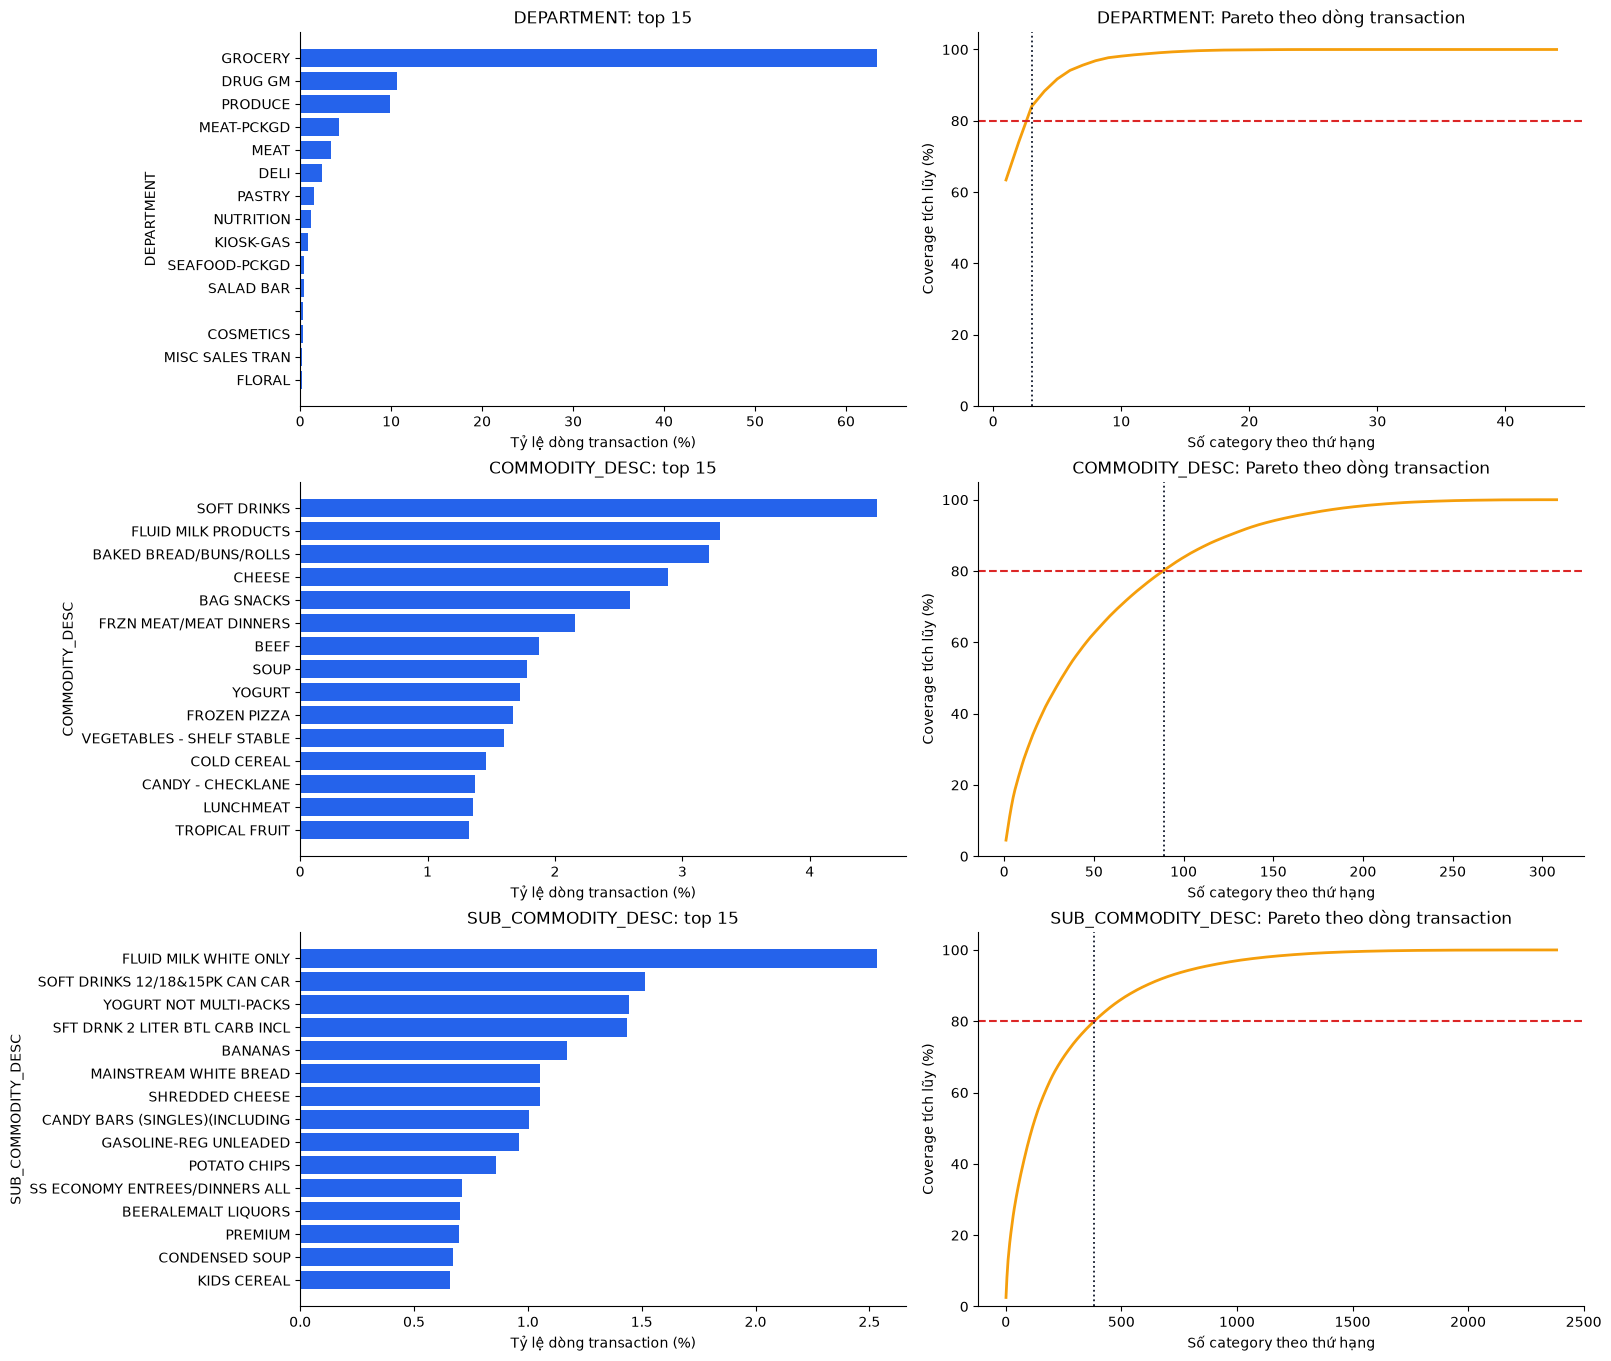

In [64]:
category_figure, category_axes = plt.subplots(
    len(CATEGORY_COLUMNS), 2,
    figsize=(16, 4.5 * len(CATEGORY_COLUMNS)),
    layout="constrained",
)
for row_index, category_column in enumerate(CATEGORY_COLUMNS):
    profile = category_profiles[category_column]
    top_axis, pareto_axis = category_axes[row_index]
    top_profile = profile.head(CATEGORY_TOP_N).sort_values("n_lines")
    top_axis.barh(
        [str(value) for value in top_profile.index],
        top_profile["line_pct"],
        color="#2563EB",
    )
    top_axis.set(
        title=f"{category_column}: top {CATEGORY_TOP_N}",
        xlabel="Tỷ lệ dòng transaction (%)", ylabel=category_column,
    )
    category_rank = np.arange(1, len(profile) + 1)
    pareto_axis.plot(
        category_rank, profile["cumulative_line_pct"],
        color="#F59E0B", linewidth=2,
    )
    pareto_axis.axhline(80, color="#DC2626", linestyle="--", linewidth=1.5)
    pareto_axis.axvline(
        int(category_top10_coverage.loc[
            category_top10_coverage["category"].eq(category_column),
            "categories_to_80pct",
        ].iloc[0]),
        color="#0F172A", linestyle=":", linewidth=1.3,
    )
    pareto_axis.set(
        title=f"{category_column}: Pareto theo dòng transaction",
        xlabel="Số category theo thứ hạng", ylabel="Coverage tích lũy (%)",
        ylim=(0, 105),
    )
    for axis in (top_axis, pareto_axis):
        axis.spines[["top", "right"]].set_visible(False)
plt.show()

### 7.5. Đóng góp doanh số (SALES_VALUE) theo Department, Commodity và Department × Commodity

Kiểm tra xem ngành hàng (`DEPARTMENT`), nhóm mặt hàng (`COMMODITY_DESC` - thường được gọi là commodity / community), và cặp kết hợp (`DEPARTMENT × COMMODITY_DESC`) nào tạo ra tổng doanh số `SALES_VALUE` lớn nhất.

In [ ]:
# Đảm bảo SALES_VALUE là kiểu số hợp lệ
transaction_detail["SALES_VALUE"] = pd.to_numeric(transaction_detail["SALES_VALUE"], errors="coerce")
total_sales_overall = float(transaction_detail["SALES_VALUE"].sum())

# 1. Top DEPARTMENT tạo ra SALES_VALUE nhiều nhất
sales_by_dept = (
    transaction_detail
    .groupby("DEPARTMENT", observed=True)
    .agg(
        total_sales_value=("SALES_VALUE", "sum"),
        mean_sales_value=("SALES_VALUE", "mean"),
        n_lines=("SALES_VALUE", "count"),
    )
    .assign(sales_pct=lambda df: df["total_sales_value"] / total_sales_overall * 100)
    .sort_values(by="total_sales_value", ascending=False)
    .assign(cum_sales_pct=lambda df: df["sales_pct"].cumsum())
)

# 2. Top COMMODITY_DESC (Commodity / Community) tạo ra SALES_VALUE nhiều nhất
sales_by_commodity = (
    transaction_detail
    .groupby("COMMODITY_DESC", observed=True)
    .agg(
        total_sales_value=("SALES_VALUE", "sum"),
        mean_sales_value=("SALES_VALUE", "mean"),
        n_lines=("SALES_VALUE", "count"),
    )
    .assign(sales_pct=lambda df: df["total_sales_value"] / total_sales_overall * 100)
    .sort_values(by="total_sales_value", ascending=False)
    .assign(cum_sales_pct=lambda df: df["sales_pct"].cumsum())
)

# 3. Top DEPARTMENT × COMMODITY_DESC tạo ra SALES_VALUE nhiều nhất
sales_by_dept_commodity = (
    transaction_detail
    .groupby(["DEPARTMENT", "COMMODITY_DESC"], observed=True)
    .agg(
        total_sales_value=("SALES_VALUE", "sum"),
        mean_sales_value=("SALES_VALUE", "mean"),
        n_lines=("SALES_VALUE", "count"),
    )
    .assign(sales_pct=lambda df: df["total_sales_value"] / total_sales_overall * 100)
    .sort_values(by="total_sales_value", ascending=False)
    .assign(cum_sales_pct=lambda df: df["sales_pct"].cumsum())
)

print("=== TOP 10 DEPARTMENT TẠO RA SALES_VALUE NHIỀU NHẤT ===")
display(sales_by_dept.head(10))

print("\n=== TOP 10 COMMODITY (COMMUNITY) TẠO RA SALES_VALUE NHIỀU NHẤT ===")
display(sales_by_commodity.head(10))

print("\n=== TOP 10 DEPARTMENT × COMMODITY TẠO RA SALES_VALUE NHIỀU NHẤT ===")
display(sales_by_dept_commodity.head(10))


In [ ]:
# Trực quan hóa Top 10 của từng cấp phân loại theo SALES_VALUE
fig_sales, axes_sales = plt.subplots(1, 3, figsize=(20, 6), layout="constrained")

# 1. Top Department
top_d = sales_by_dept.head(10).sort_values("total_sales_value")
axes_sales[0].barh([str(x) for x in top_d.index], top_d["total_sales_value"] / 1e6, color="#2563EB")
axes_sales[0].set_title("Top 10 Department theo SALES_VALUE ($M)", fontsize=12, fontweight="bold")
axes_sales[0].set_xlabel("Tổng SALES_VALUE (triệu $)")

# 2. Top Commodity
top_c = sales_by_commodity.head(10).sort_values("total_sales_value")
axes_sales[1].barh([str(x) for x in top_c.index], top_c["total_sales_value"] / 1e6, color="#059669")
axes_sales[1].set_title("Top 10 Commodity (Community) theo SALES_VALUE ($M)", fontsize=12, fontweight="bold")
axes_sales[1].set_xlabel("Tổng SALES_VALUE (triệu $)")

# 3. Top Department x Commodity
top_dc = sales_by_dept_commodity.head(10).sort_values("total_sales_value")
dc_labels = [f"{d} | {c}" for d, c in top_dc.index]
axes_sales[2].barh(dc_labels, top_dc["total_sales_value"] / 1e6, color="#D97706")
axes_sales[2].set_title("Top 10 Dept × Commodity theo SALES_VALUE ($M)", fontsize=12, fontweight="bold")
axes_sales[2].set_xlabel("Tổng SALES_VALUE (triệu $)")

for ax in axes_sales:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.show()


#### Kết luận phân tích doanh số (SALES_VALUE):
- **Department tạo ra `SALES_VALUE` nhiều nhất**: **`GROCERY`** đứng đầu áp đảo với **$4,093,814.14** (chiếm **50.81%** tổng doanh thu toàn hệ thống). Theo sau là **`DRUG GM`** ($1,055,358.03 - **13.10%**), **`PRODUCE`** ($557,452.11 - **6.92%**), **`MEAT`** ($548,786.81 - **6.81%**) và **`KIOSK-GAS`** ($544,222.28 - **6.75%**). Top 5 ngành hàng này chiếm đến **84.39%** tổng doanh thu.
- **Commodity (Community) tạo ra `SALES_VALUE` nhiều nhất**: **`COUPON/MISC ITEMS`** dẫn đầu với **$639,878.56** (chiếm **7.94%** tổng doanh số, trong đó phần lớn là doanh thu nhiên liệu/xăng tại Kiosk Gas). Kế tiếp là các ngành hàng thực phẩm thiết yếu: **`SOFT DRINKS`** ($327,647.30 - **4.07%**), **`BEEF`** ($312,103.22 - **3.87%**), **`FLUID MILK PRODUCTS`** ($205,356.05 - **2.55%**) và **`CHEESE`** ($189,528.18 - **2.35%**).
- **Department × Commodity tạo ra `SALES_VALUE` nhiều nhất**: Cặp kết hợp **`KIOSK-GAS | COUPON/MISC ITEMS`** tạo ra doanh số lớn nhất toàn chuỗi với **$514,685.72** (chiếm **6.39%** tổng sales). Xếp sau lần lượt là các cặp chủ lực: **`GROCERY | SOFT DRINKS`** ($327,647.30 - **4.07%**), **`MEAT | BEEF`** ($312,103.22 - **3.87%**), **`GROCERY | FLUID MILK PRODUCTS`** ($205,356.05 - **2.55%**) và **`GROCERY | CHEESE`** ($189,528.18 - **2.35%**).


## 8. Categorical Distribution Summary (df.describe categorical)\n
\n
Thống kê phân phối các cột phân loại (count, unique, top, freq, missing_rate) tương đương df.describe(include=['O', 'category']).

In [67]:
report.categorical_summary

,table,column,count,n_unique,top,freq,top_pct
0,product,DEPARTMENT,92338,43,GROCERY,39021,42.26
1,product,BRAND,92353,2,National,78537,85.04
2,product,COMMODITY_DESC,92338,307,GREETING CARDS/WRAP/PARTY SPLY,2785,3.02
3,product,SUB_COMMODITY_DESC,92338,2382,CARDS EVERYDAY,1005,1.09
4,product,CURR_SIZE_OF_PRODUCT,61746,4344,16 OZ,3924,6.36
5,demographic,AGE_DESC,801,6,45-54,288,35.96
6,demographic,MARITAL_STATUS_CODE,801,3,U,344,42.95
7,demographic,INCOME_DESC,801,12,50-74K,192,23.97
8,demographic,HOMEOWNER_DESC,801,5,Homeowner,504,62.92
9,demographic,HH_COMP_DESC,801,6,2 Adults No Kids,255,31.84
